<a href="https://colab.research.google.com/github/ShravyaPuram/FROZEN-GRID---MDP/blob/main/Frozen_grid_MDP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Reinforcement Learning assignment-1

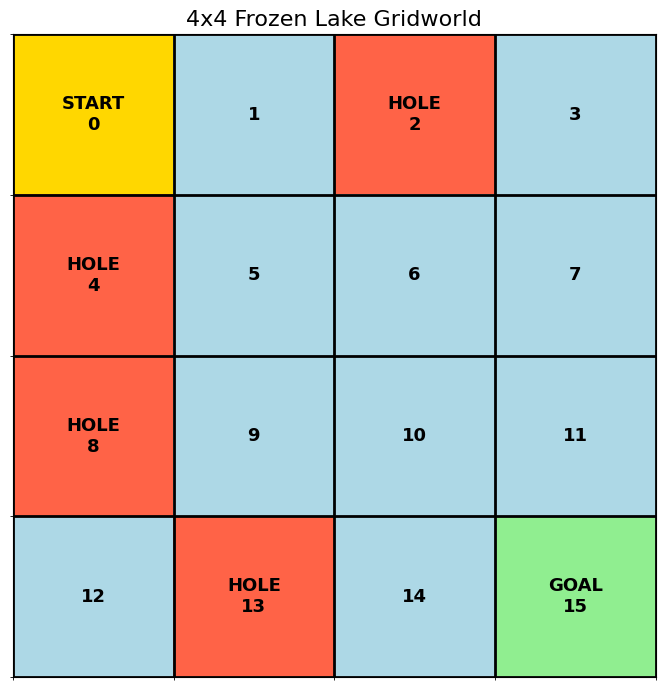

PART 1: FROZEN LAKE MDP

State space S: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Number of states: 16

Action space A: ['Left', 'Down', 'Right', 'Up']

Start state: 0
Hole states: [2, 4, 8, 13]
Goal state: 15
Terminal states: [2, 4, 8, 13, 15]

Transition probability:
Each directional outcome has probability: 0.25
Example P[0]['Right']: [(0.25, 0), (0.25, 4), (0.25, 1), (0.25, 0)]
All transition probabilities sum to 1.

Reward function:
Normal step: -0.01
Goal: 1.0
Hole: -1.0

Discount factor gamma: 0.9

MDP tuple: M = (S, A, P, R, gamma)
Finite MDP: YES
Episodic MDP: YES
Fully observable MDP: YES

OUTCOMES
1. Created the 4x4 Frozen Lake grid.
2. Defined 16 states and 4 actions.
3. Placed holes at states 2, 4, 8, and 13.
4. Placed the goal at state 15.
5. Defined transition probabilities and rewards.
6. Verified that transition distributions sum to 1.

CONCLUSION
The Frozen Lake environment has been defined as a finite,
episodic, fully observable MDP. This setup provides 

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 1. Define the MDP
GRID_SIZE = 4
NUM_STATES = 16

S = list(range(NUM_STATES))
A = ["Left", "Down", "Right", "Up"]

START_STATE = 0
GOAL_STATE = 15
HOLES = [2, 4, 8, 13]
TERMINAL_STATES = HOLES + [GOAL_STATE]

GAMMA = 0.9
LIVING_REWARD = -0.01
GOAL_REWARD = 1.0
HOLE_REWARD = -1.0

P_DIRECTION = 0.25

MOVEMENTS = {
    "Left": (0, -1),
    "Down": (1, 0),
    "Right": (0, 1),
    "Up": (-1, 0)
}

# 2. Draw the grid
grid = np.zeros((GRID_SIZE, GRID_SIZE))

for hole in HOLES:
    grid[hole // GRID_SIZE, hole % GRID_SIZE] = 1

grid[GOAL_STATE // GRID_SIZE, GOAL_STATE % GRID_SIZE] = 2
grid[START_STATE // GRID_SIZE, START_STATE % GRID_SIZE] = 3

cmap = ListedColormap([
    "lightblue",
    "tomato",
    "lightgreen",
    "gold"
])

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(grid, cmap=cmap, vmin=0, vmax=3)

for state in S:
    row = state // GRID_SIZE
    col = state % GRID_SIZE

    if state == START_STATE:
        label = f"START\n{state}"
    elif state == GOAL_STATE:
        label = f"GOAL\n{state}"
    elif state in HOLES:
        label = f"HOLE\n{state}"
    else:
        label = str(state)

    ax.text(col, row, label, ha="center", va="center",
            fontsize=13, fontweight="bold")

ax.set_xticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
ax.set_yticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
ax.grid(which="minor", color="black", linewidth=2)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("4x4 Frozen Lake Gridworld", fontsize=16)

plt.tight_layout()
plt.show()

# 3. Define the next-state function
def get_next_state(state, direction):
    row = state // GRID_SIZE
    col = state % GRID_SIZE

    dr, dc = MOVEMENTS[direction]

    new_row = row + dr
    new_col = col + dc

    if not (0 <= new_row < GRID_SIZE and
            0 <= new_col < GRID_SIZE):
        return state

    return new_row * GRID_SIZE + new_col

# 4. Define the transition probability model P
# P[state][action] = [(probability, next_state), ...]

P = {}

for state in S:
    P[state] = {}

    for action in A:
        if state in TERMINAL_STATES:
            P[state][action] = [(1.0, state)]
        else:
            outcomes = []

            for direction in A:
                next_state = get_next_state(state, direction)
                outcomes.append((P_DIRECTION, next_state))

            P[state][action] = outcomes

# 5. Define the reward function
def get_reward(state, next_state):
    if state in TERMINAL_STATES:
        return 0.0

    if next_state == GOAL_STATE:
        return GOAL_REWARD

    if next_state in HOLES:
        return HOLE_REWARD

    return LIVING_REWARD

# 6. Verify transition probabilities
for state in S:
    for action in A:
        total = sum(prob for prob, next_state in P[state][action])
        assert np.isclose(total, 1.0)

# 7. Define the complete MDP tuple
MDP = (S, A, P, get_reward, GAMMA)

# 8. Display the results
print("=" * 50)
print("PART 1: FROZEN LAKE MDP")
print("=" * 50)

print("\nState space S:", S)
print("Number of states:", len(S))

print("\nAction space A:", A)

print("\nStart state:", START_STATE)
print("Hole states:", HOLES)
print("Goal state:", GOAL_STATE)
print("Terminal states:", TERMINAL_STATES)

print("\nTransition probability:")
print("Each directional outcome has probability:", P_DIRECTION)
print("Example P[0]['Right']:", P[0]["Right"])
print("All transition probabilities sum to 1.")

print("\nReward function:")
print("Normal step:", LIVING_REWARD)
print("Goal:", GOAL_REWARD)
print("Hole:", HOLE_REWARD)

print("\nDiscount factor gamma:", GAMMA)

print("\nMDP tuple: M = (S, A, P, R, gamma)")
print("Finite MDP: YES")
print("Episodic MDP: YES")
print("Fully observable MDP: YES")

print("\nOUTCOMES")
print("1. Created the 4x4 Frozen Lake grid.")
print("2. Defined 16 states and 4 actions.")
print("3. Placed holes at states 2, 4, 8, and 13.")
print("4. Placed the goal at state 15.")
print("5. Defined transition probabilities and rewards.")
print("6. Verified that transition distributions sum to 1.")

print("\nCONCLUSION")
print("The Frozen Lake environment has been defined as a finite,")
print("episodic, fully observable MDP. This setup provides the")
print("foundation for policy evaluation, policy iteration,")
print("and value iteration.")

PART 2: POLICY EVALUATION RESULTS

Uniform random policy: pi(a|s) = 0.25
Discount factor gamma: 0.9
Holes: [2, 4, 8, 13]
Goal: 15
Iterations required: 66

Final state-value function V_pi:
[-0.782461 -0.768238  0.       -0.592716  0.       -0.719247 -0.552483
 -0.304418  0.       -0.731489 -0.287371  0.141093 -0.918182  0.
 -0.089882  0.      ]

State-value grid:
 -0.78246   -0.76824    0.00000   -0.59272
  0.00000   -0.71925   -0.55248   -0.30442
  0.00000   -0.73149   -0.28737    0.14109
 -0.91818    0.00000   -0.08988    0.00000


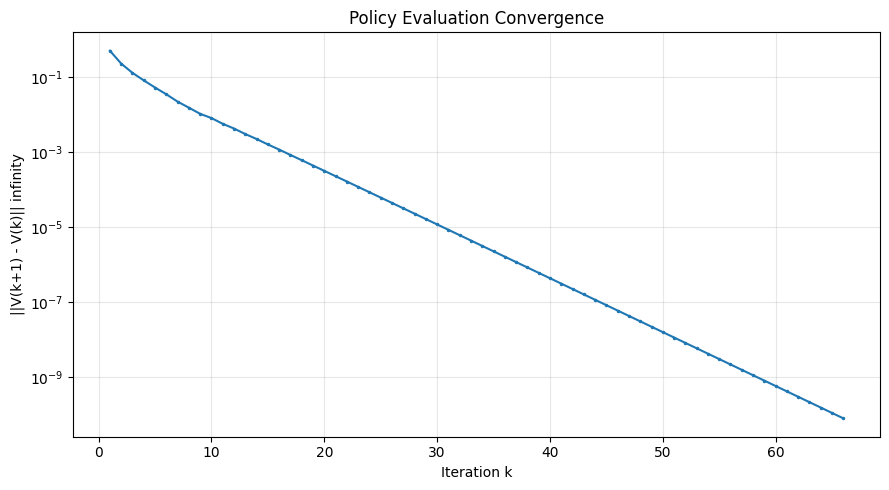

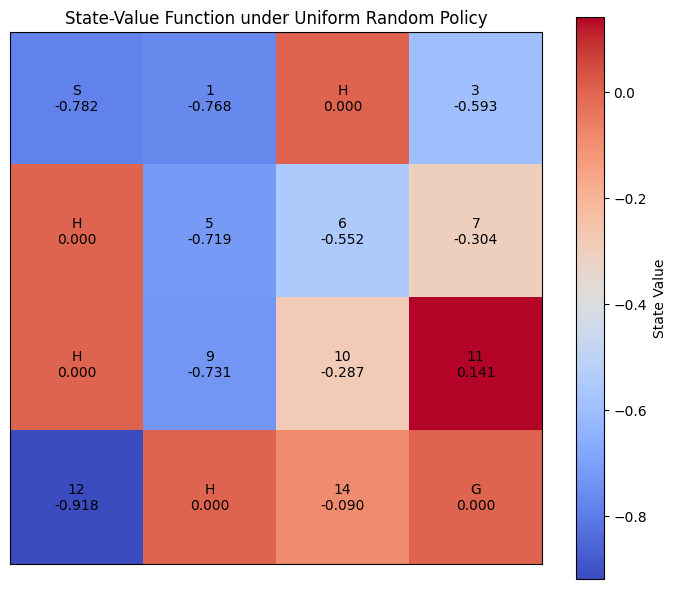


Q_pi(s,a) for every state-action pair:
Action order: ['Left', 'Down', 'Right', 'Up']
State  0: [-0.782461 -0.782461 -0.782461 -0.782461]
State  1: [-0.768238 -0.768238 -0.768238 -0.768238]
State  2: [0. 0. 0. 0.]
State  3: [-0.592716 -0.592716 -0.592716 -0.592716]
State  4: [0. 0. 0. 0.]
State  5: [-0.719247 -0.719247 -0.719247 -0.719247]
State  6: [-0.552483 -0.552483 -0.552483 -0.552483]
State  7: [-0.304418 -0.304418 -0.304418 -0.304418]
State  8: [0. 0. 0. 0.]
State  9: [-0.731489 -0.731489 -0.731489 -0.731489]
State 10: [-0.287371 -0.287371 -0.287371 -0.287371]
State 11: [0.141093 0.141093 0.141093 0.141093]
State 12: [-0.918182 -0.918182 -0.918182 -0.918182]
State 13: [0. 0. 0. 0.]
State 14: [-0.089882 -0.089882 -0.089882 -0.089882]
State 15: [0. 0. 0. 0.]

First two iterations:
V_0: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
V_1: [-0.2575 -0.2575  0.     -0.2575  0.     -0.2575 -0.2575 -0.01    0.
 -0.505  -0.01    0.2425 -0.505   0.     -0.005   0.    ]
V_2: [-0.4313 -0

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# PART 2: POLICY EVALUATION
# ============================================================

# 1. Environment setup
GRID_SIZE = 4
NUM_STATES = 16

S = list(range(NUM_STATES))
A = ["Left", "Down", "Right", "Up"]

START_STATE = 0
GOAL_STATE = 15
HOLES = [2, 4, 8, 13]
TERMINAL_STATES = HOLES + [GOAL_STATE]

GAMMA = 0.9
LIVING_REWARD = -0.01
GOAL_REWARD = 1.0
HOLE_REWARD = -1.0

ACTIONS = {
    "Left": (0, -1),
    "Down": (1, 0),
    "Right": (0, 1),
    "Up": (-1, 0)
}

# Uniform random policy
POLICY_PROB = 1.0 / len(A)


# ============================================================
# 2. Transition model
# ============================================================

def get_next_state(state, direction):
    row = state // GRID_SIZE
    col = state % GRID_SIZE

    dr, dc = ACTIONS[direction]

    new_row = row + dr
    new_col = col + dc

    if not (0 <= new_row < GRID_SIZE and
            0 <= new_col < GRID_SIZE):
        return state

    return new_row * GRID_SIZE + new_col


def get_reward(state, next_state):
    if state in TERMINAL_STATES:
        return 0.0

    if next_state == GOAL_STATE:
        return GOAL_REWARD

    if next_state in HOLES:
        return HOLE_REWARD

    return LIVING_REWARD


# P[s][a] contains (probability, next_state) pairs.
# Each of the four directional outcomes has probability 0.25.

P = {}

for s in S:
    P[s] = {}

    for a in A:
        if s in TERMINAL_STATES:
            P[s][a] = [(1.0, s)]
        else:
            P[s][a] = [
                (0.25, get_next_state(s, direction))
                for direction in A
            ]


# ============================================================
# 3. Iterative policy evaluation
# ============================================================

def policy_evaluation(theta=1e-10, max_iterations=10000):
    V = np.zeros(NUM_STATES)

    convergence_deltas = []
    value_history = [V.copy()]

    for iteration in range(max_iterations):
        V_new = np.zeros(NUM_STATES)

        for s in S:

            # Terminal states have value zero after termination
            if s in TERMINAL_STATES:
                V_new[s] = 0.0
                continue

            value = 0.0

            # Average over all actions under the random policy
            for a in A:
                action_value = 0.0

                # Average over transition outcomes
                for probability, next_state in P[s][a]:
                    reward = get_reward(s, next_state)

                    action_value += probability * (
                        reward + GAMMA * V[next_state]
                    )

                value += POLICY_PROB * action_value

            V_new[s] = value

        # Infinity norm: maximum absolute state-value change
        delta = np.max(np.abs(V_new - V))

        convergence_deltas.append(delta)
        value_history.append(V_new.copy())

        V = V_new

        if delta < theta:
            break

    return V, convergence_deltas, value_history, iteration + 1


# Run policy evaluation
V_pi, deltas, value_history, total_iterations = policy_evaluation()


# ============================================================
# 4. Display the convergence results
# ============================================================

print("=" * 60)
print("PART 2: POLICY EVALUATION RESULTS")
print("=" * 60)

print("\nUniform random policy: pi(a|s) = 0.25")
print("Discount factor gamma:", GAMMA)
print("Holes:", HOLES)
print("Goal:", GOAL_STATE)
print("Iterations required:", total_iterations)

print("\nFinal state-value function V_pi:")
print(np.round(V_pi, 6))

print("\nState-value grid:")

for row in range(GRID_SIZE):
    values = V_pi[row * GRID_SIZE:(row + 1) * GRID_SIZE]
    print("  ".join(f"{value:9.5f}" for value in values))


# ============================================================
# 5. Plot the convergence graph
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(deltas) + 1),
    deltas,
    marker=".",
    markersize=3
)

plt.xlabel("Iteration k")
plt.ylabel("||V(k+1) - V(k)|| infinity")
plt.title("Policy Evaluation Convergence")
plt.grid(True, alpha=0.3)
plt.yscale("log")
plt.tight_layout()
plt.show()


# ============================================================
# 6. Plot state values as a heatmap
# ============================================================

value_grid = V_pi.reshape(GRID_SIZE, GRID_SIZE)

plt.figure(figsize=(7, 6))

plt.imshow(value_grid, cmap="coolwarm", interpolation="nearest")
plt.colorbar(label="State Value")

for s in S:
    row = s // GRID_SIZE
    col = s % GRID_SIZE

    if s == START_STATE:
        label = f"S\n{V_pi[s]:.3f}"
    elif s == GOAL_STATE:
        label = "G\n0.000"
    elif s in HOLES:
        label = f"H\n0.000"
    else:
        label = f"{s}\n{V_pi[s]:.3f}"

    plt.text(
        col, row, label,
        ha="center",
        va="center",
        fontsize=10,
        color="black"
    )

plt.title("State-Value Function under Uniform Random Policy")
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()


# ============================================================
# 7. Calculate Q_pi(s,a) for every state-action pair
# ============================================================

Q_pi = np.zeros((NUM_STATES, len(A)))

for s in S:
    for a_idx, a in enumerate(A):

        if s in TERMINAL_STATES:
            Q_pi[s, a_idx] = 0.0
            continue

        q_value = 0.0

        for probability, next_state in P[s][a]:
            reward = get_reward(s, next_state)

            q_value += probability * (
                reward + GAMMA * V_pi[next_state]
            )

        Q_pi[s, a_idx] = q_value

print("\nQ_pi(s,a) for every state-action pair:")
print("Action order:", A)

for s in S:
    print(f"State {s:2d}: {np.round(Q_pi[s], 6)}")


# ============================================================
# 8. Verify the first two iterations manually
# ============================================================

V0 = np.zeros(NUM_STATES)
V1 = np.zeros(NUM_STATES)
V2 = np.zeros(NUM_STATES)

# First iteration
for s in S:
    if s in TERMINAL_STATES:
        continue

    for a in A:
        for probability, next_state in P[s][a]:
            V1[s] += (
                POLICY_PROB
                * probability
                * get_reward(s, next_state)
            )

# Second iteration
for s in S:
    if s in TERMINAL_STATES:
        continue

    for a in A:
        for probability, next_state in P[s][a]:
            reward = get_reward(s, next_state)

            V2[s] += POLICY_PROB * probability * (
                reward + GAMMA * V1[next_state]
            )

print("\nFirst two iterations:")
print("V_0:", np.round(V0, 4))
print("V_1:", np.round(V1, 4))
print("V_2:", np.round(V2, 4))

print("\nManual verification at state 1:")
print("V_0(1) =", V0[1])
print("V_1(1) =", V1[1])
print("V_2(1) =", V2[1])

print("\nPart 2 completed successfully.")

PART 3.1: POLICY ITERATION

Policy after improvement step 1
----------------------------------------
    S     ←/↓/→/↑     H     ←/↓/→/↑ 
    H     ←/↓/→/↑  ←/↓/→/↑  ←/↓/→/↑ 
    H     ←/↓/→/↑  ←/↓/→/↑  ←/↓/→/↑ 
 ←/↓/→/↑     H     ←/↓/→/↑     G    

Policy stabilized at improvement step 1.

Policy evaluation sweeps in each improvement:
[66]

Final policy evaluation sweeps:
66

Total policy improvement steps: 1

Final value function from policy iteration
 -0.7825  -0.7682   0.0000  -0.5927
  0.0000  -0.7192  -0.5525  -0.3044
  0.0000  -0.7315  -0.2874   0.1411
 -0.9182   0.0000  -0.0899   0.0000

Final policy from policy iteration
----------------------------------------
    S     ←/↓/→/↑     H     ←/↓/→/↑ 
    H     ←/↓/→/↑  ←/↓/→/↑  ←/↓/→/↑ 
    H     ←/↓/→/↑  ←/↓/→/↑  ←/↓/→/↑ 
 ←/↓/→/↑     H     ←/↓/→/↑     G    

PART 3.2: VALUE ITERATION

Value iteration convergence sweeps: 66

Final value function from value iteration
 -0.7825  -0.7682   0.0000  -0.5927
  0.0000  -0.7192  -0.5525 

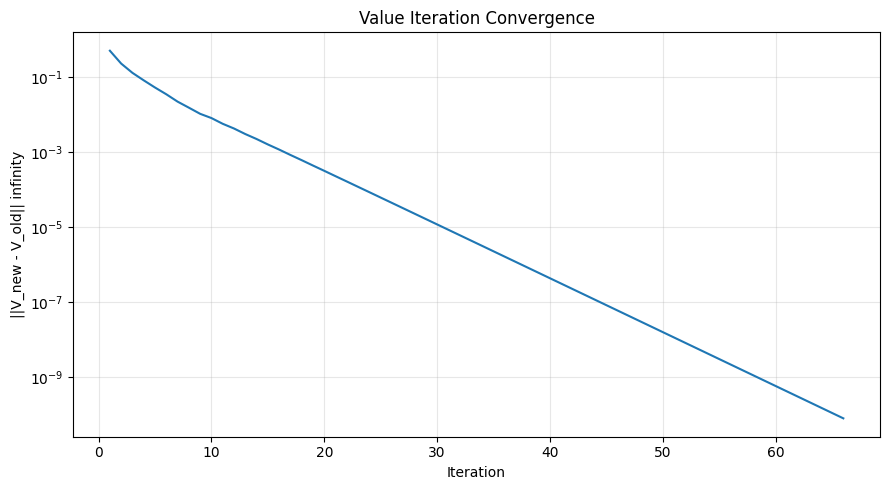

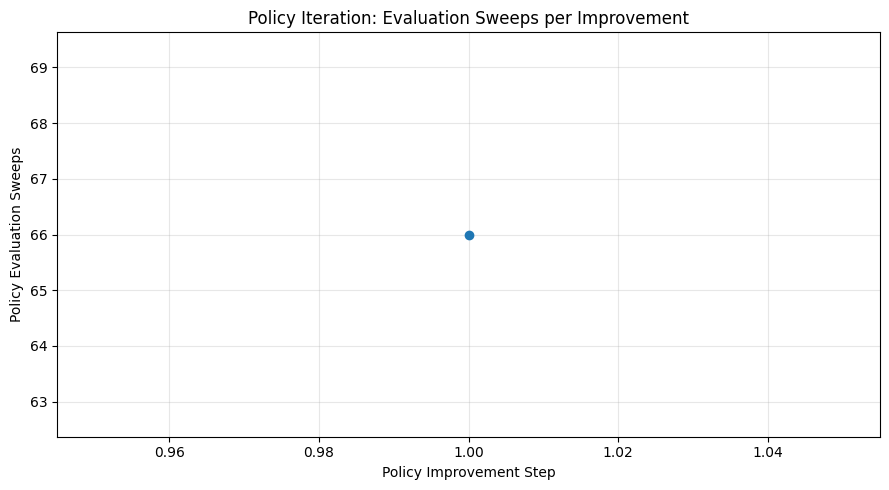


ANALYSIS AND CONCLUSION

1. Policy iteration alternates between policy evaluation and
   policy improvement. It stops when the policy is unchanged.

2. Value iteration repeatedly applies the Bellman optimality
   update and then extracts a greedy policy.

3. For gamma < 1, the Bellman expectation and optimality
   operators are contractions in the infinity norm, with
   contraction factor gamma. Repeated updates therefore
   converge toward their respective fixed points.

4. Policy iteration can require fewer policy improvement
   steps because each evaluation solves for the value function
   of the current policy, approximately or exactly.

5. Value iteration performs a partial evaluation through
   repeated Bellman optimality updates, often requiring more
   sweeps to propagate value information across the grid.

6. Important for this assignment: with four equally likely
   directional outcomes for every action, the transition
   distribution does not depend on the chosen action.
  

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# PART 3: POLICY ITERATION AND VALUE ITERATION
# ============================================================

# 1. ENVIRONMENT SETUP

GRID_SIZE = 4
NUM_STATES = 16

S = list(range(NUM_STATES))
A = ["Left", "Down", "Right", "Up"]

START_STATE = 0
GOAL_STATE = 15
HOLES = [2, 4, 8, 13]
TERMINAL_STATES = HOLES + [GOAL_STATE]

GAMMA = 0.9
LIVING_REWARD = -0.01
GOAL_REWARD = 1.0
HOLE_REWARD = -1.0

THETA = 1e-10
MAX_ITERATIONS = 10000

MOVEMENTS = {
    "Left": (0, -1),
    "Down": (1, 0),
    "Right": (0, 1),
    "Up": (-1, 0)
}

NUM_ACTIONS = len(A)


# ============================================================
# 2. TRANSITION MODEL
# ============================================================

def get_next_state(state, action_direction):
    row = state // GRID_SIZE
    col = state % GRID_SIZE

    dr, dc = MOVEMENTS[action_direction]

    new_row = row + dr
    new_col = col + dc

    if not (
        0 <= new_row < GRID_SIZE
        and 0 <= new_col < GRID_SIZE
    ):
        return state

    return new_row * GRID_SIZE + new_col


def get_reward(state, next_state):
    if state in TERMINAL_STATES:
        return 0.0

    if next_state == GOAL_STATE:
        return GOAL_REWARD

    if next_state in HOLES:
        return HOLE_REWARD

    return LIVING_REWARD


# P[s][a] = list of (probability, next_state)
# Assumption: four directional outcomes, each with probability 0.25.

P = {}

for s in S:
    P[s] = {}

    for a in A:
        if s in TERMINAL_STATES:
            P[s][a] = [(1.0, s)]
        else:
            P[s][a] = [
                (0.25, get_next_state(s, direction))
                for direction in A
            ]


# ============================================================
# 3. POLICY EVALUATION
# ============================================================

def evaluate_policy(policy, theta=THETA):
    V = np.zeros(NUM_STATES)

    for iteration in range(MAX_ITERATIONS):

        V_new = np.zeros(NUM_STATES)

        for s in S:

            if s in TERMINAL_STATES:
                V_new[s] = 0.0
                continue

            value = 0.0

            for a_idx, a in enumerate(A):

                action_value = 0.0

                for probability, next_state in P[s][a]:
                    reward = get_reward(s, next_state)

                    action_value += probability * (
                        reward + GAMMA * V[next_state]
                    )

                value += policy[s, a_idx] * action_value

            V_new[s] = value

        delta = np.max(np.abs(V_new - V))
        V = V_new

        if delta < theta:
            return V, iteration + 1

    return V, MAX_ITERATIONS


# ============================================================
# 4. HELPER: COMPUTE Q VALUES
# ============================================================

def compute_q_values(V):

    Q = np.zeros((NUM_STATES, NUM_ACTIONS))

    for s in S:

        if s in TERMINAL_STATES:
            Q[s, :] = 0.0
            continue

        for a_idx, a in enumerate(A):

            q_value = 0.0

            for probability, next_state in P[s][a]:
                reward = get_reward(s, next_state)

                q_value += probability * (
                    reward + GAMMA * V[next_state]
                )

            Q[s, a_idx] = q_value

    return Q


# ============================================================
# 5. HELPER: DISPLAY POLICY
# ============================================================

def display_policy(policy, title):

    symbols = {
        "Left": "←",
        "Down": "↓",
        "Right": "→",
        "Up": "↑"
    }

    print("\n" + title)
    print("-" * 40)

    for row in range(GRID_SIZE):

        row_symbols = []

        for col in range(GRID_SIZE):

            s = row * GRID_SIZE + col

            if s == START_STATE:
                symbol = "S"
            elif s == GOAL_STATE:
                symbol = "G"
            elif s in HOLES:
                symbol = "H"
            else:
                best_actions = np.flatnonzero(
                    np.isclose(policy[s], np.max(policy[s]))
                )

                # Show every tied optimal action.
                symbol = "/".join(
                    symbols[A[i]] for i in best_actions
                )

            row_symbols.append(f"{symbol:^9}")

        print("".join(row_symbols))


def display_value_grid(V, title):

    print("\n" + title)

    for row in range(GRID_SIZE):

        values = []

        for col in range(GRID_SIZE):

            s = row * GRID_SIZE + col

            if s in TERMINAL_STATES:
                values.append(f"{0.0:8.4f}")
            else:
                values.append(f"{V[s]:8.4f}")

        print(" ".join(values))


# ============================================================
# PART 3.1: POLICY ITERATION
# ============================================================

print("=" * 65)
print("PART 3.1: POLICY ITERATION")
print("=" * 65)

# Start with a uniform random policy.
policy = np.full(
    (NUM_STATES, NUM_ACTIONS),
    1.0 / NUM_ACTIONS
)

# Terminal states do not require action selection.
for s in TERMINAL_STATES:
    policy[s, :] = 0.0

policy_history = []
policy_evaluation_iterations = []
policy_stable = False

for improvement_step in range(1, 101):

    # Step 1: Evaluate the current policy.
    V, eval_iterations = evaluate_policy(policy)

    policy_evaluation_iterations.append(eval_iterations)

    # Step 2: Calculate Q(s,a).
    Q = compute_q_values(V)

    # Step 3: Improve the policy greedily.
    new_policy = np.zeros_like(policy)

    for s in S:

        if s in TERMINAL_STATES:
            continue

        best_value = np.max(Q[s])

        best_actions = np.flatnonzero(
            np.isclose(Q[s], best_value, atol=1e-9)
        )

        # Split probability equally among tied best actions.
        new_policy[s, best_actions] = (
            1.0 / len(best_actions)
        )

    policy_history.append(new_policy.copy())

    # Display every policy improvement step.
    display_policy(
        new_policy,
        f"Policy after improvement step {improvement_step}"
    )

    # Check whether the policy has stabilized.
    if np.allclose(new_policy, policy, atol=1e-9):
        policy = new_policy
        policy_stable = True
        print(
            f"\nPolicy stabilized at improvement step "
            f"{improvement_step}."
        )
        break

    policy = new_policy


# Evaluate the final policy.
V_policy_iteration, final_eval_iterations = evaluate_policy(policy)

print("\nPolicy evaluation sweeps in each improvement:")
print(policy_evaluation_iterations)

print("\nFinal policy evaluation sweeps:")
print(final_eval_iterations)

print("\nTotal policy improvement steps:", len(policy_history))

display_value_grid(
    V_policy_iteration,
    "Final value function from policy iteration"
)

display_policy(
    policy,
    "Final policy from policy iteration"
)


# ============================================================
# PART 3.2: VALUE ITERATION
# ============================================================

print("\n" + "=" * 65)
print("PART 3.2: VALUE ITERATION")
print("=" * 65)

V_vi = np.zeros(NUM_STATES)
value_iteration_deltas = []

for iteration in range(MAX_ITERATIONS):

    V_new = np.zeros(NUM_STATES)

    for s in S:

        if s in TERMINAL_STATES:
            V_new[s] = 0.0
            continue

        action_values = []

        for a in A:

            q_value = 0.0

            for probability, next_state in P[s][a]:
                reward = get_reward(s, next_state)

                q_value += probability * (
                    reward + GAMMA * V_vi[next_state]
                )

            action_values.append(q_value)

        V_new[s] = max(action_values)

    delta = np.max(np.abs(V_new - V_vi))

    value_iteration_deltas.append(delta)
    V_vi = V_new

    if delta < THETA:
        break

value_iteration_iterations = iteration + 1

# Recover the greedy policy.
Q_vi = compute_q_values(V_vi)

greedy_policy = np.zeros((NUM_STATES, NUM_ACTIONS))

for s in S:

    if s in TERMINAL_STATES:
        continue

    best_value = np.max(Q_vi[s])

    best_actions = np.flatnonzero(
        np.isclose(Q_vi[s], best_value, atol=1e-9)
    )

    greedy_policy[s, best_actions] = (
        1.0 / len(best_actions)
    )

print("\nValue iteration convergence sweeps:",
      value_iteration_iterations)

display_value_grid(
    V_vi,
    "Final value function from value iteration"
)

display_policy(
    greedy_policy,
    "Greedy policy recovered from value iteration"
)


# ============================================================
# 6. COMPARE THE RESULTS
# ============================================================

print("\n" + "=" * 65)
print("POLICY ITERATION VS VALUE ITERATION")
print("=" * 65)

max_value_difference = np.max(
    np.abs(V_policy_iteration - V_vi)
)

print("Maximum absolute value difference:",
      max_value_difference)

print(
    "Value functions approximately match:",
    np.allclose(
        V_policy_iteration,
        V_vi,
        atol=1e-6
    )
)

print(
    "Policy iteration stabilized:",
    policy_stable
)

print(
    "Policy comparison:",
    np.allclose(
        policy,
        greedy_policy,
        atol=1e-6
    )
)

print(
    "\nNote: If all actions have identical transition distributions, "
    "all actions tie in every non-terminal state. Therefore, "
    "multiple optimal policies exist."
)


# ============================================================
# 7. CONVERGENCE GRAPHS
# ============================================================

# Graph 1: Value iteration convergence
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(value_iteration_deltas) + 1),
    value_iteration_deltas
)

plt.xlabel("Iteration")
plt.ylabel("||V_new - V_old|| infinity")
plt.title("Value Iteration Convergence")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Graph 2: Policy evaluation sweeps per improvement step
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(policy_evaluation_iterations) + 1),
    policy_evaluation_iterations,
    marker="o"
)

plt.xlabel("Policy Improvement Step")
plt.ylabel("Policy Evaluation Sweeps")
plt.title("Policy Iteration: Evaluation Sweeps per Improvement")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 8. ANALYSIS AND CONCLUSION
# ============================================================

print("\n" + "=" * 65)
print("ANALYSIS AND CONCLUSION")
print("=" * 65)

print("""
1. Policy iteration alternates between policy evaluation and
   policy improvement. It stops when the policy is unchanged.

2. Value iteration repeatedly applies the Bellman optimality
   update and then extracts a greedy policy.

3. For gamma < 1, the Bellman expectation and optimality
   operators are contractions in the infinity norm, with
   contraction factor gamma. Repeated updates therefore
   converge toward their respective fixed points.

4. Policy iteration can require fewer policy improvement
   steps because each evaluation solves for the value function
   of the current policy, approximately or exactly.

5. Value iteration performs a partial evaluation through
   repeated Bellman optimality updates, often requiring more
   sweeps to propagate value information across the grid.

6. Important for this assignment: with four equally likely
   directional outcomes for every action, the transition
   distribution does not depend on the chosen action.
   Therefore, no action is better than another, and the model
   cannot demonstrate a meaningful directional optimal policy.
""")

PART 4: EXACT VS ITERATIVE POLICY EVALUATION

Policy: Uniform random policy
Discount factor: 0.9
Hole states: [2, 4, 8, 13]
Goal state: 15

Policy transition matrix P_pi:
[[0.5  0.25 0.   0.   0.25 0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.  ]
 [0.25 0.25 0.25 0.   0.   0.25 0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.  ]
 [0.   0.   1.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.  ]
 [0.   0.   0.25 0.5  0.   0.   0.   0.25 0.   0.   0.   0.   0.   0.
  0.   0.  ]
 [0.   0.   0.   0.   1.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.  ]
 [0.   0.25 0.   0.   0.25 0.   0.25 0.   0.   0.25 0.   0.   0.   0.
  0.   0.  ]
 [0.   0.   0.25 0.   0.   0.25 0.   0.25 0.   0.   0.25 0.   0.   0.
  0.   0.  ]
 [0.   0.   0.   0.25 0.   0.   0.25 0.25 0.   0.   0.   0.25 0.   0.
  0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   1.   0.   0.   0.   0.   0.
  0.   0.  ]
 [0.   0.   0.   0.   0.   0.25 0.   0.   0.25 0.   0.25 0.   0.   0.25
  0.   0. 

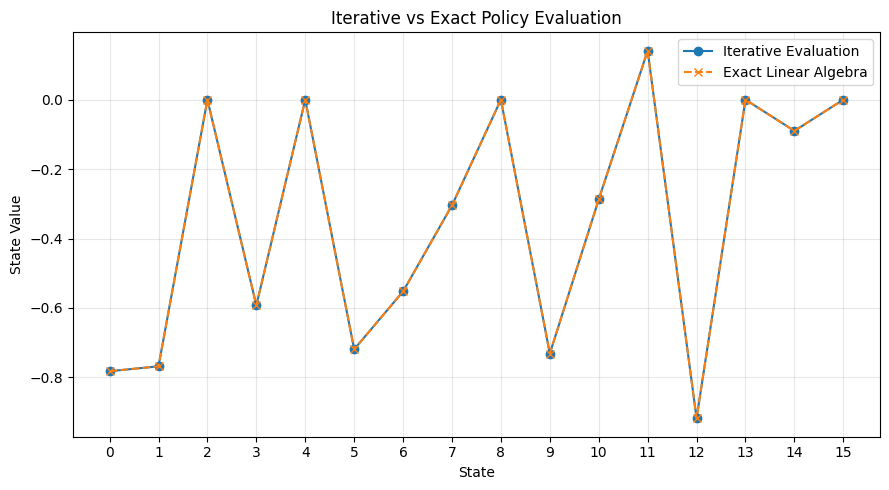


CONCLUSION

1. Iterative policy evaluation estimates the value function
   through repeated Bellman updates.

2. Exact policy evaluation solves the linear system
   (I - gamma * P_pi) V_pi = R_pi.

3. The maximum absolute difference measures the numerical
   discrepancy between the two methods.

4. Direct linear algebra is practical for small state spaces,
   but becomes computationally expensive for large problems.

5. Reinforcement learning methods can scale by using iterative
   updates, sampled experience, function approximation, and
   learning from selected states or transitions instead of
   explicitly inverting a large matrix.



In [6]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# PART 4: FROM ITERATIVE TO EXACT SOLUTION
# ============================================================

# 1. Environment setup
GRID_SIZE = 4
NUM_STATES = 16

S = list(range(NUM_STATES))
A = ["Left", "Down", "Right", "Up"]

START_STATE = 0
GOAL_STATE = 15
HOLES = [2, 4, 8, 13]
TERMINAL_STATES = HOLES + [GOAL_STATE]

GAMMA = 0.9
LIVING_REWARD = -0.01
GOAL_REWARD = 1.0
HOLE_REWARD = -1.0

THETA = 1e-12

MOVEMENTS = {
    "Left": (0, -1),
    "Down": (1, 0),
    "Right": (0, 1),
    "Up": (-1, 0)
}

NUM_ACTIONS = len(A)

# Uniform random policy
POLICY_PROB = 1.0 / NUM_ACTIONS


# ============================================================
# 2. Transition model
# ============================================================

def get_next_state(state, direction):
    row = state // GRID_SIZE
    col = state % GRID_SIZE

    dr, dc = MOVEMENTS[direction]

    new_row = row + dr
    new_col = col + dc

    if not (
        0 <= new_row < GRID_SIZE
        and 0 <= new_col < GRID_SIZE
    ):
        return state

    return new_row * GRID_SIZE + new_col


# P[s][a] = list of (probability, next_state) pairs
# Assumption: all four directional outcomes have probability 0.25.

P = {}

for s in S:
    P[s] = {}

    for a in A:
        if s in TERMINAL_STATES:
            P[s][a] = [(1.0, s)]
        else:
            P[s][a] = [
                (0.25, get_next_state(s, direction))
                for direction in A
            ]


# ============================================================
# 3. Reward function
# ============================================================

def get_reward(state, next_state):
    if state in TERMINAL_STATES:
        return 0.0

    if next_state == GOAL_STATE:
        return GOAL_REWARD

    if next_state in HOLES:
        return HOLE_REWARD

    return LIVING_REWARD


# ============================================================
# 4. Iterative policy evaluation
# ============================================================

def iterative_policy_evaluation():

    V = np.zeros(NUM_STATES)

    for iteration in range(100000):

        V_new = np.zeros(NUM_STATES)

        for s in S:

            # Terminal states have zero value after termination.
            if s in TERMINAL_STATES:
                V_new[s] = 0.0
                continue

            value = 0.0

            for a in A:

                action_value = 0.0

                for probability, next_state in P[s][a]:

                    reward = get_reward(s, next_state)

                    action_value += probability * (
                        reward + GAMMA * V[next_state]
                    )

                value += POLICY_PROB * action_value

            V_new[s] = value

        delta = np.max(np.abs(V_new - V))
        V = V_new

        if delta < THETA:
            return V, iteration + 1

    return V, 100000


V_iterative, iterative_iterations = iterative_policy_evaluation()


# ============================================================
# 5. Construct P_pi and R_pi
# ============================================================

P_pi = np.zeros((NUM_STATES, NUM_STATES))
R_pi = np.zeros(NUM_STATES)

for s in S:

    if s in TERMINAL_STATES:
        # Absorbing terminal states with zero post-terminal reward.
        P_pi[s, s] = 1.0
        R_pi[s] = 0.0
        continue

    for a in A:

        for probability, next_state in P[s][a]:

            weighted_probability = POLICY_PROB * probability

            P_pi[s, next_state] += weighted_probability

            reward = get_reward(s, next_state)

            R_pi[s] += weighted_probability * reward


# ============================================================
# 6. Solve using exact linear algebra
# ============================================================

# Bellman equation:
# V_pi = R_pi + gamma * P_pi * V_pi
#
# Rearranging:
# (I - gamma * P_pi) V_pi = R_pi
#
# Therefore:
# V_pi = inverse(I - gamma * P_pi) * R_pi

I = np.eye(NUM_STATES)

M = I - GAMMA * P_pi

V_exact = np.linalg.solve(M, R_pi)

# Alternatively, the requested matrix-inversion formula is:
V_inverse = np.linalg.inv(M) @ R_pi


# ============================================================
# 7. Compare iterative and exact results
# ============================================================

max_difference = np.max(np.abs(V_iterative - V_exact))

print("=" * 65)
print("PART 4: EXACT VS ITERATIVE POLICY EVALUATION")
print("=" * 65)

print("\nPolicy: Uniform random policy")
print("Discount factor:", GAMMA)
print("Hole states:", HOLES)
print("Goal state:", GOAL_STATE)

print("\nPolicy transition matrix P_pi:")
print(np.round(P_pi, 4))

print("\nExpected reward vector R_pi:")
print(np.round(R_pi, 6))

print("\nIterative value function:")
print(np.round(V_iterative, 8))

print("\nExact value function using np.linalg.solve:")
print(np.round(V_exact, 8))

print("\nExact value function using matrix inversion:")
print(np.round(V_inverse, 8))

print("\nIterations required by iterative evaluation:")
print(iterative_iterations)

print("\nMaximum absolute difference:")
print(f"{max_difference:.12e}")

print("\nAre the iterative and exact results approximately equal?")
print(np.allclose(V_iterative, V_exact, atol=1e-9))


# ============================================================
# 8. Display values in grid format
# ============================================================

print("\nIterative Value Grid:")

for row in range(GRID_SIZE):
    values = V_iterative[row * GRID_SIZE:(row + 1) * GRID_SIZE]
    print("  ".join(f"{v:10.6f}" for v in values))

print("\nExact Value Grid:")

for row in range(GRID_SIZE):
    values = V_exact[row * GRID_SIZE:(row + 1) * GRID_SIZE]
    print("  ".join(f"{v:10.6f}" for v in values))


# ============================================================
# 9. Plot comparison
# ============================================================

plt.figure(figsize=(9, 5))

states = np.arange(NUM_STATES)

plt.plot(
    states,
    V_iterative,
    marker="o",
    label="Iterative Evaluation"
)

plt.plot(
    states,
    V_exact,
    marker="x",
    linestyle="--",
    label="Exact Linear Algebra"
)

plt.xlabel("State")
plt.ylabel("State Value")
plt.title("Iterative vs Exact Policy Evaluation")
plt.xticks(states)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 10. Conclusion
# ============================================================

print("\n" + "=" * 65)
print("CONCLUSION")
print("=" * 65)

print("""
1. Iterative policy evaluation estimates the value function
   through repeated Bellman updates.

2. Exact policy evaluation solves the linear system
   (I - gamma * P_pi) V_pi = R_pi.

3. The maximum absolute difference measures the numerical
   discrepancy between the two methods.

4. Direct linear algebra is practical for small state spaces,
   but becomes computationally expensive for large problems.

5. Reinforcement learning methods can scale by using iterative
   updates, sampled experience, function approximation, and
   learning from selected states or transitions instead of
   explicitly inverting a large matrix.
""")

QUESTION 1: EFFECT OF DISCOUNT FACTOR

Discount factor gamma = 0.0
Iterations: 2
Value function:
[[-0.2575 -0.2575  0.     -0.2575]
 [ 0.     -0.2575 -0.2575 -0.01  ]
 [ 0.     -0.505  -0.01    0.2425]
 [-0.505   0.     -0.005   0.    ]]
Greedy policy:
     S      Left/Down/Right/Up     H      Left/Down/Right/Up
     H      Left/Down/Right/UpLeft/Down/Right/UpLeft/Down/Right/Up
     H      Left/Down/Right/UpLeft/Down/Right/UpLeft/Down/Right/Up
Left/Down/Right/Up     H      Left/Down/Right/Up     G      

Discount factor gamma = 0.5
Iterations: 25
Value function:
[[-0.41224 -0.41342  0.      -0.35555]
 [ 0.      -0.42173 -0.33104 -0.07332]
 [ 0.      -0.56937 -0.09326  0.25335]
 [-0.67333  0.      -0.01904  0.     ]]
Greedy policy:
     S      Left/Down/Right/Up     H      Left/Down/Right/Up
     H      Left/Down/Right/UpLeft/Down/Right/UpLeft/Down/Right/Up
     H      Left/Down/Right/UpLeft/Down/Right/UpLeft/Down/Right/Up
Left/Down/Right/Up     H      Left/Down/Right/Up     G      

Di

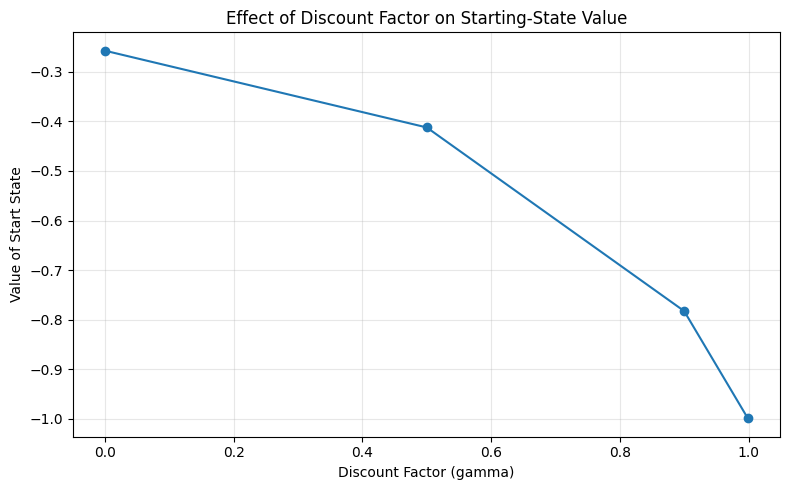


QUESTION 2: EFFECT OF LIVING REWARD

Living reward = -0.01
Iterations: 66
Value function:
[[-0.78246 -0.76824  0.      -0.59272]
 [ 0.      -0.71925 -0.55248 -0.30442]
 [ 0.      -0.73149 -0.28737  0.14109]
 [-0.91818  0.      -0.08988  0.     ]]
Starting-state value: -0.7824609506143139

Living reward = 0.0
Iterations: 66
Value function:
[[-0.75943 -0.74526  0.      -0.56351]
 [ 0.      -0.69648 -0.52451 -0.26636]
 [ 0.      -0.71458 -0.25722  0.17058]
 [-0.90909  0.      -0.07468  0.     ]]
Starting-state value: -0.7594258297778391

Compare the greedy policies:
State  0: living reward -0.01 -> ['Left', 'Down', 'Right', 'Up'], living reward 0.00 -> ['Left', 'Down', 'Right', 'Up']
State  1: living reward -0.01 -> ['Left', 'Down', 'Right', 'Up'], living reward 0.00 -> ['Left', 'Down', 'Right', 'Up']
State  3: living reward -0.01 -> ['Left', 'Down', 'Right', 'Up'], living reward 0.00 -> ['Left', 'Down', 'Right', 'Up']
State  5: living reward -0.01 -> ['Left', 'Down', 'Right', 'Up'], liv

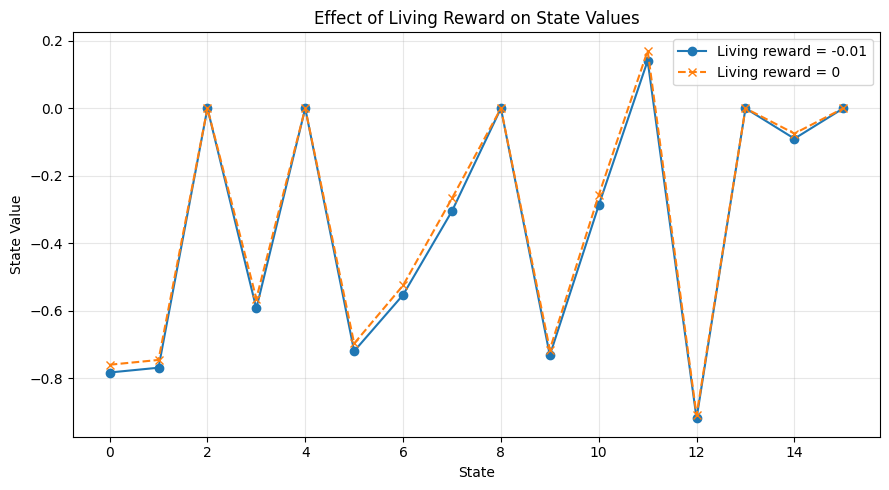


QUESTION 3: MODEL-FREE REINFORCEMENT LEARNING

In Parts 1-4, the transition model P and reward function R
were explicitly defined.

In model-free reinforcement learning, the agent does not
need to know P or R in advance.

Instead, the agent:
1. Interacts with the environment.
2. Observes the next state and received reward.
3. Updates its value estimates using experience.
4. Repeats the process to improve its decisions.

A common model-free algorithm is Q-learning.


Example Q-learning update:

Q(s,a) = Q(s,a) + alpha *
         [r + gamma * max_a' Q(s',a') - Q(s,a)]

Here:
alpha = learning rate
gamma = discount factor
r = observed reward
s' = observed next state

PART 5: FINAL SUMMARY
Question 1: Compared gamma = 0, 0.5, 0.9, and 0.999.
Question 2: Compared living rewards -0.01 and 0.
Question 3: Explained how model-free RL learns from experience.
All experiments used holes at states 2, 4, 8, and 13.
Part 5 completed.


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# PART 5: EXPLORATION QUESTIONS
# ============================================================

# 1. ENVIRONMENT SETUP

GRID_SIZE = 4
NUM_STATES = 16

S = list(range(NUM_STATES))
A = ["Left", "Down", "Right", "Up"]

START_STATE = 0
GOAL_STATE = 15
HOLES = [2, 4, 8, 13]
TERMINAL_STATES = HOLES + [GOAL_STATE]

MOVEMENTS = {
    "Left": (0, -1),
    "Down": (1, 0),
    "Right": (0, 1),
    "Up": (-1, 0)
}

GOAL_REWARD = 1.0
HOLE_REWARD = -1.0

THETA = 1e-10
MAX_ITERATIONS = 100000


# ============================================================
# 2. TRANSITION MODEL
# ============================================================

# This matches Parts 1-4:
# Four directional outcomes, each with probability 0.25,
# regardless of the selected action.

def get_next_state(state, direction):
    row = state // GRID_SIZE
    col = state % GRID_SIZE

    dr, dc = MOVEMENTS[direction]

    new_row = row + dr
    new_col = col + dc

    if not (
        0 <= new_row < GRID_SIZE
        and 0 <= new_col < GRID_SIZE
    ):
        return state

    return new_row * GRID_SIZE + new_col


P = {}

for s in S:
    P[s] = {}

    for a in A:
        if s in TERMINAL_STATES:
            P[s][a] = [(1.0, s)]
        else:
            P[s][a] = [
                (0.25, get_next_state(s, direction))
                for direction in A
            ]


# ============================================================
# 3. VALUE ITERATION FUNCTION
# ============================================================

def value_iteration(gamma, living_reward=-0.01):

    V = np.zeros(NUM_STATES)

    def reward(state, next_state):

        if state in TERMINAL_STATES:
            return 0.0

        if next_state == GOAL_STATE:
            return GOAL_REWARD

        if next_state in HOLES:
            return HOLE_REWARD

        return living_reward

    deltas = []

    for iteration in range(MAX_ITERATIONS):

        V_new = np.zeros(NUM_STATES)

        for s in S:

            if s in TERMINAL_STATES:
                V_new[s] = 0.0
                continue

            action_values = []

            for a in A:

                q = 0.0

                for probability, next_state in P[s][a]:

                    r = reward(s, next_state)

                    q += probability * (
                        r + gamma * V[next_state]
                    )

                action_values.append(q)

            V_new[s] = max(action_values)

        delta = np.max(np.abs(V_new - V))
        deltas.append(delta)

        V = V_new

        if delta < THETA:
            break

    # Recover a greedy policy.
    Q = np.zeros((NUM_STATES, len(A)))

    for s in S:

        if s in TERMINAL_STATES:
            continue

        for a_idx, a in enumerate(A):

            for probability, next_state in P[s][a]:

                Q[s, a_idx] += probability * (
                    reward(s, next_state)
                    + gamma * V[next_state]
                )

    policy = {}

    for s in S:

        if s in TERMINAL_STATES:
            policy[s] = "Terminal"
        else:
            best_actions = np.flatnonzero(
                np.isclose(Q[s], np.max(Q[s]), atol=1e-8)
            )

            policy[s] = [
                A[i] for i in best_actions
            ]

    return V, policy, deltas, iteration + 1


# ============================================================
# QUESTION 1:
# EFFECT OF DIFFERENT DISCOUNT FACTORS
# ============================================================

print("=" * 65)
print("QUESTION 1: EFFECT OF DISCOUNT FACTOR")
print("=" * 65)

discount_factors = [0.0, 0.5, 0.9, 0.999]

discount_results = {}

for gamma in discount_factors:

    V, policy, deltas, iterations = value_iteration(
        gamma=gamma,
        living_reward=-0.01
    )

    discount_results[gamma] = {
        "V": V,
        "policy": policy,
        "deltas": deltas,
        "iterations": iterations
    }

    print(f"\nDiscount factor gamma = {gamma}")
    print("Iterations:", iterations)
    print("Value function:")

    print(np.round(V.reshape(4, 4), 5))

    print("Greedy policy:")

    for row in range(4):

        row_policy = []

        for col in range(4):

            state = row * 4 + col

            if state == START_STATE:
                symbol = "S"
            elif state == GOAL_STATE:
                symbol = "G"
            elif state in HOLES:
                symbol = "H"
            else:
                symbol = "/".join(
                    discount_results[gamma]["policy"][state]
                )

            row_policy.append(f"{symbol:^12}")

        print("".join(row_policy))


# Plot the starting-state value for each discount factor.
plt.figure(figsize=(8, 5))

plt.plot(
    discount_factors,
    [
        discount_results[g]["V"][START_STATE]
        for g in discount_factors
    ],
    marker="o"
)

plt.xlabel("Discount Factor (gamma)")
plt.ylabel("Value of Start State")
plt.title("Effect of Discount Factor on Starting-State Value")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# QUESTION 2:
# EFFECT OF CHANGING THE LIVING REWARD
# ============================================================

print("\n" + "=" * 65)
print("QUESTION 2: EFFECT OF LIVING REWARD")
print("=" * 65)

living_rewards = [-0.01, 0.0]

reward_results = {}

for living_reward in living_rewards:

    V, policy, deltas, iterations = value_iteration(
        gamma=0.9,
        living_reward=living_reward
    )

    reward_results[living_reward] = {
        "V": V,
        "policy": policy,
        "deltas": deltas,
        "iterations": iterations
    }

    print(f"\nLiving reward = {living_reward}")
    print("Iterations:", iterations)

    print("Value function:")
    print(np.round(V.reshape(4, 4), 5))

    print("Starting-state value:", V[START_STATE])


print("\nCompare the greedy policies:")

for s in S:

    if s in TERMINAL_STATES:
        continue

    policy_1 = reward_results[-0.01]["policy"][s]
    policy_2 = reward_results[0.0]["policy"][s]

    print(
        f"State {s:2d}: "
        f"living reward -0.01 -> {policy_1}, "
        f"living reward 0.00 -> {policy_2}"
    )


# Plot state values for the two living rewards.
plt.figure(figsize=(9, 5))

states = np.arange(NUM_STATES)

plt.plot(
    states,
    reward_results[-0.01]["V"],
    marker="o",
    label="Living reward = -0.01"
)

plt.plot(
    states,
    reward_results[0.0]["V"],
    marker="x",
    linestyle="--",
    label="Living reward = 0"
)

plt.xlabel("State")
plt.ylabel("State Value")
plt.title("Effect of Living Reward on State Values")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# QUESTION 3:
# MODEL-FREE REINFORCEMENT LEARNING DEMONSTRATION
# ============================================================

print("\n" + "=" * 65)
print("QUESTION 3: MODEL-FREE REINFORCEMENT LEARNING")
print("=" * 65)

print("""
In Parts 1-4, the transition model P and reward function R
were explicitly defined.

In model-free reinforcement learning, the agent does not
need to know P or R in advance.

Instead, the agent:
1. Interacts with the environment.
2. Observes the next state and received reward.
3. Updates its value estimates using experience.
4. Repeats the process to improve its decisions.

A common model-free algorithm is Q-learning.
""")

print("\nExample Q-learning update:")

print("""
Q(s,a) = Q(s,a) + alpha *
         [r + gamma * max_a' Q(s',a') - Q(s,a)]
""")

print("Here:")
print("alpha = learning rate")
print("gamma = discount factor")
print("r = observed reward")
print("s' = observed next state")


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("PART 5: FINAL SUMMARY")
print("=" * 65)

print("Question 1: Compared gamma = 0, 0.5, 0.9, and 0.999.")
print("Question 2: Compared living rewards -0.01 and 0.")
print("Question 3: Explained how model-free RL learns from experience.")
print("All experiments used holes at states 2, 4, 8, and 13.")
print("Part 5 completed.")